# 12 · Mock coding test B — binary classification, class imbalance, and a two-task network

**Rules.** Same as mock A: **150 minutes**, one sitting, no autocomplete / internet / AI / other notebooks; allowed are your homework, the official course materials and `help(...)`.

This mock deliberately changes the details you have been practising, to test whether you understood the ideas or memorised one version of them:

- the file is parsed with the `csv` module,
- missing values are filled with the **mean** and flagged with **1 = missing**,
- features are **min-max** scaled instead of standardised,
- mini-batches come from **your own generator** — `Dataset`/`DataLoader` are *not allowed* here,
- the classifier is built the **lecturer's way** (sigmoid in the model, `BCELoss`),
- the classes are imbalanced, and the last task trains regression and classification **together**.

`check(...)` lines print ✅ / ❌. For the training tasks they only test loose sanity ranges.

---
**The data.** `machines.csv` — sensor snapshots of industrial machines, comma separated, with a header:

`temp_c, vibration, pressure, rpm, hours_since_service, type, shift, wear, failure`

- `type` is `A`, `B` or `C`; `shift` is `day` or `night`
- `vibration` and `pressure` are sometimes missing (empty field)
- `wear` (0–100) is measured later in the workshop — a **label**
- `failure` (0/1): did the machine fail in the following week — a **label**

In [1]:
import copy
import csv
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

import sys; sys.path.insert(0, "..")
from dnd_utils import check, DATA, reference_mock_b

REF = reference_mock_b()
PATH = DATA / "machines.csv"
with open(PATH) as f:
    for _ in range(4): print(f.readline().rstrip())

temp_c,vibration,pressure,rpm,hours_since_service,type,shift,wear,failure
64.9,3.74,5.26,1479,965,B,day,100.0,1
56.9,,7.17,1680,168,B,night,29.8,0
55.4,2.00,6.92,1293,225,A,day,26.9,0


## **1** · Load (15 min)

With `csv.reader`, build `raw`: shape `(2400, 9)`, `float32`, columns in file order; `type` → 0/1/2 for A/B/C; `shift` → 0 for day, 1 for night; empty → `np.nan`.

In [2]:
# implement your solution BELOW
TYPE_CODE = {"A": 0.0, "B": 1.0, "C": 2.0}
SHIFT_CODE = {"day": 0.0, "night": 1.0}

data_rows = []
with open(PATH, newline="") as f:
    reader = csv.reader(f)
    header = next(reader)
    type_col, shift_col = header.index("type"), header.index("shift")
    for row in reader:
        values = []
        for j, text in enumerate(row):
            if text == "":
                values.append(float("nan"))
            elif j == type_col:
                values.append(TYPE_CODE[text])
            elif j == shift_col:
                values.append(SHIFT_CODE[text])
            else:
                values.append(float(text))
        data_rows.append(values)
raw = np.array(data_rows, dtype=np.float32)
print(raw.shape, np.isnan(raw).sum(axis=0), "failure rate:", raw[:, 8].mean())
# implement your solution ABOVE
check("1 · raw", lambda: raw.shape == (2400, 9) and raw.dtype == np.float32 and np.allclose(raw, REF["raw"], equal_nan=True))

(2400, 9) [  0 157 121   0   0   0   0   0   0] failure rate: 0.13
✅ 1 · raw


True

## **2** · Shuffle and split (5 min)

Permutation `np.random.default_rng(7).permutation(n)`; split **70 % / 15 % / 15 %** (`int(n * 0.7)`, `int(n * 0.15)`, rest) into `split_train`, `split_val`, `split_test`.

In [3]:
# implement your solution BELOW
n = raw.shape[0]
shuffled = raw[np.random.default_rng(7).permutation(n)]
n_train, n_val = int(n * 0.7), int(n * 0.15)
split_train, split_val, split_test = shuffled[:n_train], shuffled[n_train:n_train + n_val], shuffled[n_train + n_val:]
print(split_train.shape, split_val.shape, split_test.shape)
# implement your solution ABOVE
check("2 · splits", lambda: all(a.shape == b.shape and np.allclose(a, b, equal_nan=True) for a, b in zip((split_train, split_val, split_test), REF["splits"])))

(1680, 9) (360, 9) (360, 9)
✅ 2 · splits


True

## **3** · Pre-process (20 min)

Build `X_train`, `X_val`, `X_test` (`float32`, **11 columns**):

| columns | content |
|---|---|
| 0–4 | `temp_c`, `vibration`, `pressure`, `rpm`, `hours_since_service` — missing values replaced by the **training mean** of the column, then **min-max scaled** to `[0, 1]` using the training minimum and maximum (computed after the replacement) |
| 5 | `shift` (0/1) |
| 6–8 | one-hot of `type` (A, B, C) |
| 9–10 | indicators for `vibration` and `pressure`: **1 if the value was missing**, else 0 |

Also create the label vectors `wear_train/val/test` and `fail_train/val/test` (1-D, `float32`). Neither label may appear among the inputs.

In [4]:
# implement your solution BELOW
fill = np.nanmean(split_train[:, [1, 2]], axis=0)                       # training means of vibration and pressure

def build(split):
    num = split[:, :5].copy()
    num[:, 1:3] = np.where(np.isnan(num[:, 1:3]), fill, num[:, 1:3])
    shift = split[:, 6, None]
    type_onehot = (split[:, 5, None] == np.arange(3)[None, :]).astype(np.float32)
    missing = np.isnan(split[:, 1:3]).astype(np.float32)                # 1 = missing (taken BEFORE filling: from `split`, not `num`)
    return num, np.concatenate([shift, type_onehot, missing], axis=1)

num_train, _ = build(split_train)
lo, hi = num_train.min(axis=0), num_train.max(axis=0)                   # training min / max

def finish(split):
    num, rest = build(split)
    return np.concatenate([(num - lo) / (hi - lo), rest], axis=1).astype(np.float32)

X_train, X_val, X_test = finish(split_train), finish(split_val), finish(split_test)
wear_train, wear_val, wear_test = split_train[:, 7], split_val[:, 7], split_test[:, 7]
fail_train, fail_val, fail_test = split_train[:, 8], split_val[:, 8], split_test[:, 8]
print(X_train.shape, X_train[:, :5].min(axis=0), X_train[:, :5].max(axis=0))
print("validation range:", X_val[:, :5].min().round(3), X_val[:, :5].max().round(3), "(may leave [0, 1] -- that is correct)")
# implement your solution ABOVE
check("3 · X matrices", lambda: all(a.shape == b.shape and a.dtype == np.float32 and np.allclose(a, b, atol=1e-5) for a, b in zip((X_train, X_val, X_test), REF["X"])))
check("3 · training features lie exactly in [0, 1]", lambda: X_train[:, :5].min() == 0 and X_train[:, :5].max() == 1)
check("3 · labels", lambda: all(np.array_equal(a, b) for a, b in zip((wear_train, wear_val, wear_test, fail_train, fail_val, fail_test), REF["wear"] + REF["fail"])))

(1680, 11) [0. 0. 0. 0. 0.] [1. 1. 1. 1. 1.]
validation range: -0.044 0.926 (may leave [0, 1] -- that is correct)
✅ 3 · X matrices
✅ 3 · training features lie exactly in [0, 1]
✅ 3 · labels


True

## **4** · A mini-batch generator (15 min)

Write the generator function `batch_generator(X, labels, batch_size, shuffle, rng=None)`:

- `X`: NumPy `(n, d)`; `labels`: a **list** of one or more 1-D NumPy arrays of length `n` (one per task)
- yields tuples `(xb, l1b, l2b, …)` of `torch.float32` tensors: `xb` `(batch, d)`, every label batch `(batch, 1)`
- `shuffle=True` → a new random order from `rng` on every call; `shuffle=False` → original order

`Dataset` and `DataLoader` are not allowed in this notebook.

In [5]:
# implement your solution BELOW
def batch_generator(X, labels, batch_size, shuffle, rng=None):
    n = X.shape[0]
    order = rng.permutation(n) if shuffle else np.arange(n)
    for offset in range(0, n, batch_size):
        idx = order[offset:offset + batch_size]                                    # the same indices for X and every label
        xb = torch.tensor(X[idx], dtype=torch.float32)
        label_batches = [torch.tensor(l[idx], dtype=torch.float32)[:, None] for l in labels]
        yield (xb, *label_batches)
# implement your solution ABOVE
_g = list(batch_generator(X_train, [fail_train, wear_train], 64, False))
check("4 · number of batches and shapes", lambda: len(_g) == 27 and [tuple(t.shape) for t in _g[0]] == [(64, 11), (64, 1), (64, 1)] and _g[-1][0].shape[0] == 1680 - 26 * 64)
check("4 · dtypes", lambda: all(t.dtype == torch.float32 for t in _g[0]))
check("4 · unshuffled keeps the order", lambda: np.array_equal(torch.cat([b[2] for b in _g])[:, 0].numpy(), wear_train))
_s = list(batch_generator(X_train, [wear_train], 64, True, np.random.default_rng(0)))
check("4 · shuffled: other order, same samples, pairs intact", lambda: not np.array_equal(torch.cat([b[1] for b in _s])[:, 0].numpy(), wear_train) and np.allclose(np.sort(torch.cat([b[1] for b in _s])[:, 0].numpy()), np.sort(wear_train)) and any(np.array_equal(_s[0][0][0].numpy(), X_train[i]) for i in np.where(wear_train == _s[0][1][0, 0].item())[0]))

✅ 4 · number of batches and shapes
✅ 4 · dtypes
✅ 4 · unshuffled keeps the order
✅ 4 · shuffled: other order, same samples, pairs intact


True

## **5** · Failure classifier with early stopping (35 min)

- Model class `FailureMLP`: `11 → 32 → 16 → 1`, ReLU, **sigmoid at the output**; loss `nn.BCELoss`.
- Train with your generator (batch size 64, new shuffle each epoch), `Adam`. Record training and validation loss per epoch.
- Early stopping on the validation loss, `patience = 15`, at most 300 epochs, best weights restored automatically.
- Plot both curves with a legend and a marker at the best epoch.
- On the test set compute `test_acc`, `test_precision`, `test_recall`, `test_f1` (positive class = failure; guard against division by zero) and `baseline_acc` (always predict the training majority class).
- One comment line: is accuracy a good metric here? Why / why not?

stopped after 45 epochs, best epoch 29, best val loss 0.224


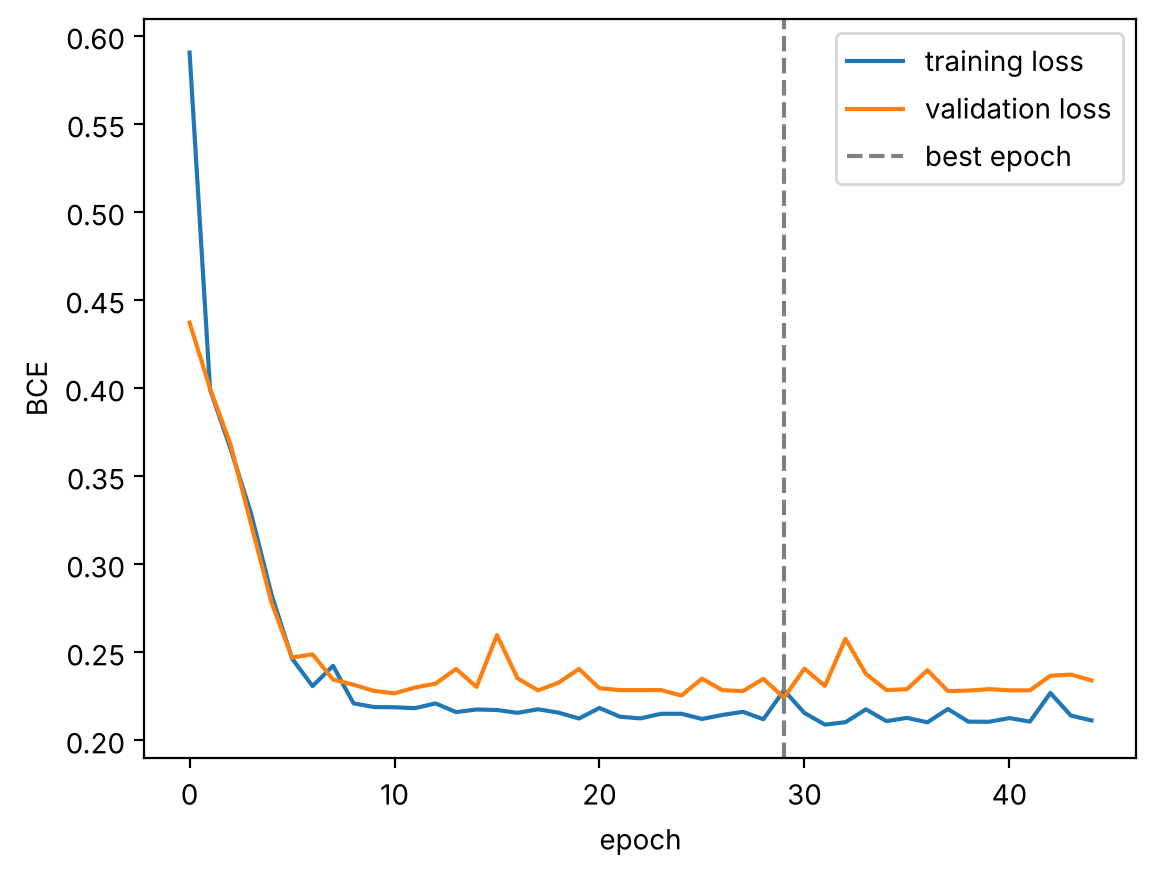

accuracy 0.933 (baseline 0.889)   precision 0.786   recall 0.550   F1 0.647
✅ 5 · model outputs probabilities of shape (batch, 1)
✅ 5 · baseline_acc
✅ 5 · metrics are consistent
✅ 5 · the classifier learned something (accuracy ≥ baseline, recall > 0.2)


True

In [6]:
# implement your solution BELOW
class FailureMLP(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(n_inputs, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(),
                                    nn.Linear(16, 1), nn.Sigmoid())
    def forward(self, x):
        return self.layers(x)

def train_classifier(loss_on_batch, seed=0, max_epochs=300, patience=15, lr=0.003):
    """loss_on_batch(pred_probs, y) -> scalar training loss. Validation always uses the plain BCE."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = FailureMLP(X_train.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    bce = nn.BCELoss()
    train_hist, val_hist = [], []
    best_val, best_epoch, best_state, bad_epochs = float("inf"), 0, None, 0
    for epoch in range(max_epochs):
        model.train()
        losses = []
        for xb, yb in batch_generator(X_train, [fail_train], 64, True, rng):       # a NEW generator every epoch
            loss = loss_on_batch(model(xb), yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            losses.append(loss.item())
        train_hist.append(np.mean(losses))

        model.eval()
        losses, sizes = [], []
        with torch.no_grad():
            for xb, yb in batch_generator(X_val, [fail_val], 64, False):
                losses.append(bce(model(xb), yb).item()); sizes.append(len(xb))
        val_hist.append(np.average(losses, weights=sizes))                         # exact mean despite the short last batch

        if val_hist[-1] < best_val:
            best_val, best_epoch, bad_epochs = val_hist[-1], epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break
    model.load_state_dict(best_state)
    return model, train_hist, val_hist, best_epoch

def test_metrics(model):
    model.eval()
    with torch.no_grad():
        probs = torch.cat([model(xb) for xb, _ in batch_generator(X_test, [fail_test], 64, False)])[:, 0].numpy()
    pred = (probs > 0.5).astype(np.float32)
    tp = int(((pred == 1) & (fail_test == 1)).sum()); fp = int(((pred == 1) & (fail_test == 0)).sum()); fn = int(((pred == 0) & (fail_test == 1)).sum())
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    return float((pred == fail_test).mean()), precision, recall, f1

model, train_hist, val_hist, best_epoch = train_classifier(nn.BCELoss())
print(f"stopped after {len(val_hist)} epochs, best epoch {best_epoch}, best val loss {val_hist[best_epoch]:.3f}")

plt.plot(train_hist, label="training loss"); plt.plot(val_hist, label="validation loss")
plt.axvline(best_epoch, color="gray", ls="--", label="best epoch")
plt.xlabel("epoch"); plt.ylabel("BCE"); plt.legend(); plt.show()

test_acc, test_precision, test_recall, test_f1 = test_metrics(model)
baseline_acc = float((fail_test == (1.0 if fail_train.mean() > 0.5 else 0.0)).mean())
print(f"accuracy {test_acc:.3f} (baseline {baseline_acc:.3f})   precision {test_precision:.3f}   recall {test_recall:.3f}   F1 {test_f1:.3f}")
# Accuracy is a poor metric here: ~87-89 % of the machines do not fail, so "never predict a failure" already scores ~0.89
# while finding zero failures. Recall / precision / F1 of the failure class say what the model is really worth.
# implement your solution ABOVE
check("5 · model outputs probabilities of shape (batch, 1)", lambda: (lambda o: o.shape == (7, 1) and 0 <= o.min() and o.max() <= 1)(model(torch.rand(7, 11))))
check("5 · baseline_acc", lambda: abs(baseline_acc - (fail_test == 0).mean()) < 1e-6)
check("5 · metrics are consistent", lambda: abs(test_f1 - (2 * test_precision * test_recall / (test_precision + test_recall) if test_precision + test_recall > 0 else 0.0)) < 1e-6)
check("5 · the classifier learned something (accuracy ≥ baseline, recall > 0.2)", lambda: test_acc >= baseline_acc and test_recall > 0.2)

## **6** · A weighted loss against the imbalance (20 min)

Missing a failure is expensive. Train a second `FailureMLP` (`model_w`) in which the loss of every **failure** sample is multiplied by `w_pos = n_negative / n_positive` (training set). Use `nn.BCELoss(reduction="none")` and do the weighting and averaging yourself. Early stopping as before, **monitoring the plain (unweighted) validation BCE**.

Report `recall_w` and `precision_w` on the test set next to the values from task 5, and comment in one line on what changed and why.

In [7]:
# implement your solution BELOW
w_pos = float((fail_train == 0).sum() / (fail_train == 1).sum())
bce_none = nn.BCELoss(reduction="none")

def weighted_bce(pred, y):
    per_sample = bce_none(pred, y)                       # (batch, 1)
    weights = torch.where(y == 1, w_pos, 1.0)            # (batch, 1) -- same shape, no broadcasting surprise
    return (per_sample * weights).mean()

model_w, train_hist_w, val_hist_w, best_epoch_w = train_classifier(weighted_bce)
acc_w, precision_w, recall_w, f1_w = test_metrics(model_w)
print(f"w_pos = {w_pos:.2f}")
print(f"plain    : accuracy {test_acc:.3f}  precision {test_precision:.3f}  recall {test_recall:.3f}  F1 {test_f1:.3f}")
print(f"weighted : accuracy {acc_w:.3f}  precision {precision_w:.3f}  recall {recall_w:.3f}  F1 {f1_w:.3f}")
# Each missed failure now costs ~6.6x more than a false alarm, so the model predicts "failure" at lower certainty:
# recall goes up (more real failures found), precision and accuracy go down (more false alarms).
# implement your solution ABOVE
check("6 · w_pos", lambda: abs(w_pos - (fail_train == 0).sum() / (fail_train == 1).sum()) < 1e-6)
check("6 · weighting did not lower the recall (normally it rises)", lambda: recall_w >= test_recall)
check("6 · ... and did not raise the precision (normally it falls)", lambda: precision_w <= test_precision + 0.02)

w_pos = 6.60
plain    : accuracy 0.933  precision 0.786  recall 0.550  F1 0.647
weighted : accuracy 0.900  precision 0.537  recall 0.725  F1 0.617
✅ 6 · w_pos
✅ 6 · weighting did not lower the recall (normally it rises)
✅ 6 · ... and did not raise the precision (normally it falls)


True

## **7** · One network, two tasks (40 min)

Predict `wear` (regression) **and** `failure` (classification) with a single network.

- Standardise the `wear` target with training statistics.
- `TwoTaskMLP`: shared layers `11 → 32 → 16` (ReLU), then two heads: `wear` (1 output) and `failure` (1 **logit** — use `nn.BCEWithLogitsLoss` here). `forward` returns both.
- Loss: `MSE(wear) + BCE(failure)`. Train 100 epochs with your generator (it already supports two label arrays), `Adam`; record the total training and validation loss per epoch and plot them.
- On the test set report `wear_rmse` **in the original wear units**, `wear_baseline_rmse` (predicting the training mean), and `fail_acc`.

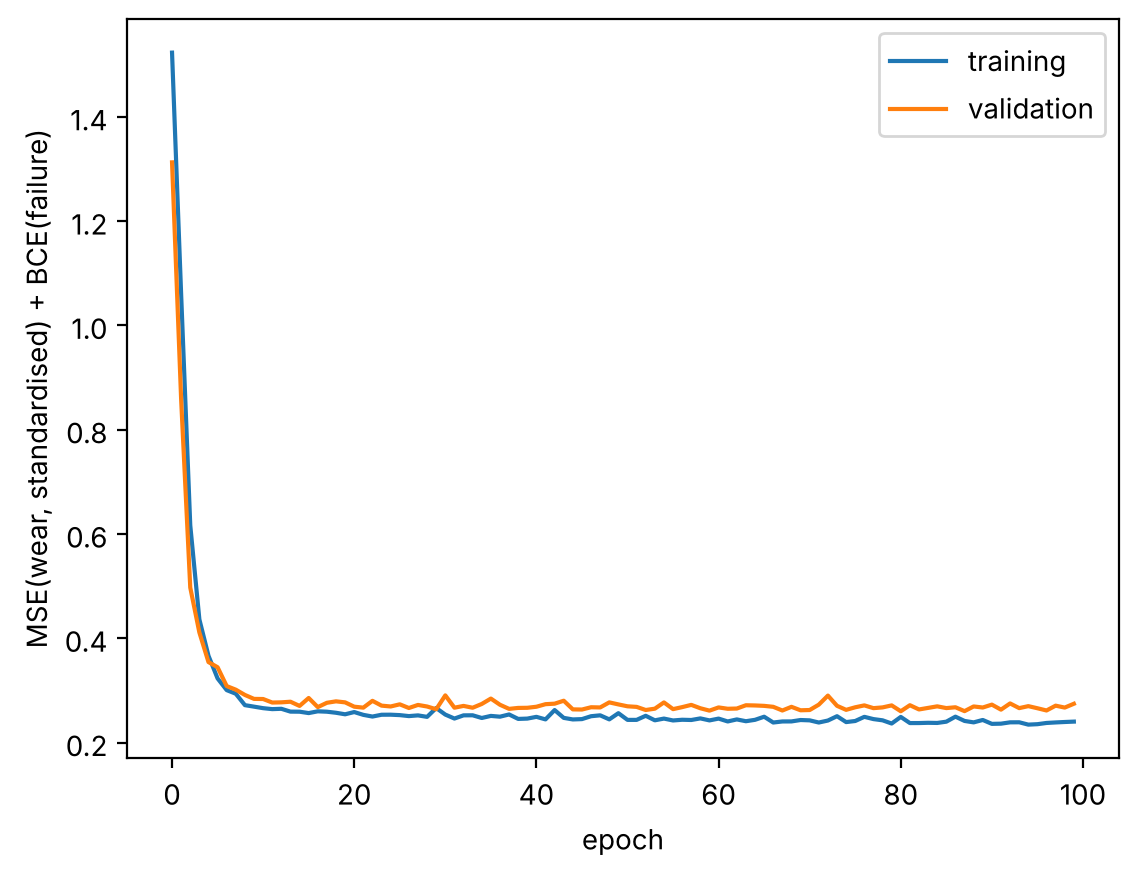

wear RMSE 4.11 (baseline 23.26)   failure accuracy 0.936 (baseline 0.889)
✅ 7 · two outputs of shape (batch, 1)
✅ 7 · baseline RMSE
✅ 7 · wear RMSE is in wear units and far below the baseline
✅ 7 · failure accuracy at least at baseline level


True

In [8]:
# implement your solution BELOW
wear_mean, wear_std = wear_train.mean(), wear_train.std()
wz_train, wz_val, wz_test = [(w - wear_mean) / wear_std for w in (wear_train, wear_val, wear_test)]

class TwoTaskMLP(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(n_inputs, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU())
        self.head_wear = nn.Linear(16, 1)
        self.head_fail = nn.Linear(16, 1)
    def forward(self, x):
        h = self.trunk(x)
        return self.head_wear(h), self.head_fail(h)

torch.manual_seed(0)
rng = np.random.default_rng(0)
model_mt = TwoTaskMLP(X_train.shape[1])
optimizer = torch.optim.Adam(model_mt.parameters(), lr=0.003)
mse_fn, bce_logits = nn.MSELoss(), nn.BCEWithLogitsLoss()

mt_train_hist, mt_val_hist = [], []
for epoch in range(100):
    model_mt.train()
    losses = []
    for xb, wb, fb in batch_generator(X_train, [wz_train, fail_train], 64, True, rng):
        wear_pred, fail_logit = model_mt(xb)
        loss = mse_fn(wear_pred, wb) + bce_logits(fail_logit, fb)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        losses.append(loss.item())
    mt_train_hist.append(np.mean(losses))

    model_mt.eval()
    losses, sizes = [], []
    with torch.no_grad():
        for xb, wb, fb in batch_generator(X_val, [wz_val, fail_val], 64, False):
            wear_pred, fail_logit = model_mt(xb)
            losses.append((mse_fn(wear_pred, wb) + bce_logits(fail_logit, fb)).item()); sizes.append(len(xb))
    mt_val_hist.append(np.average(losses, weights=sizes))

plt.plot(mt_train_hist, label="training"); plt.plot(mt_val_hist, label="validation")
plt.xlabel("epoch"); plt.ylabel("MSE(wear, standardised) + BCE(failure)"); plt.legend(); plt.show()

model_mt.eval()
with torch.no_grad():
    wear_pred, fail_logit = model_mt(torch.tensor(X_test))
wear_pred_units = wear_pred[:, 0].numpy() * wear_std + wear_mean               # back to wear units
wear_rmse = float(np.sqrt(((wear_pred_units - wear_test) ** 2).mean()))
wear_baseline_rmse = float(np.sqrt(((wear_test - wear_train.mean()) ** 2).mean()))
fail_acc = float(((fail_logit[:, 0].numpy() > 0).astype(np.float32) == fail_test).mean())
print(f"wear RMSE {wear_rmse:.2f} (baseline {wear_baseline_rmse:.2f})   failure accuracy {fail_acc:.3f} (baseline {baseline_acc:.3f})")
# implement your solution ABOVE
check("7 · two outputs of shape (batch, 1)", lambda: (lambda o: len(o) == 2 and o[0].shape == (5, 1) and o[1].shape == (5, 1))(model_mt(torch.rand(5, 11))))
check("7 · baseline RMSE", lambda: abs(wear_baseline_rmse - float(np.sqrt(((wear_test - wear_train.mean()) ** 2).mean()))) < 1e-3)
check("7 · wear RMSE is in wear units and far below the baseline", lambda: 2 < wear_rmse < 0.5 * wear_baseline_rmse)
check("7 · failure accuracy at least at baseline level", lambda: fail_acc >= baseline_acc - 0.02)

---
## After the bell

For each task write one line: *finished / finished with docs / not finished*, and the **single idea** that slowed you down most. Typical ones, and where to revise them:

| if this cost you time … | … revisit |
|---|---|
| `csv.reader`, header handling | 07, exercise 7.1 |
| fitting fill values / scaling on the training split only | 04, exercises 4.6–4.9 |
| generator mechanics, re-creating it every epoch | 05, exercises 5.3–5.4 |
| sigmoid + `BCELoss` vs logits + `BCEWithLogitsLoss` | 07, exercises 7.3–7.4, 7.10 |
| early stopping, `deepcopy` of the state | 09, exercises 9.2–9.3 |
| `reduction="none"` and weight shapes | 07, exercise 7.7 |
| two heads, loss scales, un-standardising predictions | 10 |

Then, a few days later, repeat the mock from an empty copy and try to beat your time.